# Heavy Equipment Selling Price Prediction

### The purpose of this project is to build a model that predicts TargetValue for heavy-equipment transactions.

Each row represents a finalized transaction and contains information such as machine specifications, transaction details, geographic information, and technical features.

This is a supervised regression problem because the training data contains known **TargetValue** values, and the target is a continuous numerical variable.

The model learns patterns from the training data and uses them to predict **TargetValue** for the test data.

The final submission contains:

**TransactionID** - identifies each test transaction.
**TargetValue** - the model's predicted value.


The overall workflow includes **EDA, preprocessing, feature engineering, model training and comparison, tuning, performance analysis, and final prediction**.

### Evaluation Metric  RMSLE

The competition uses **RMSLE**, which stands for **Root Mean Squared Logarithmic Error**.

The formula is:

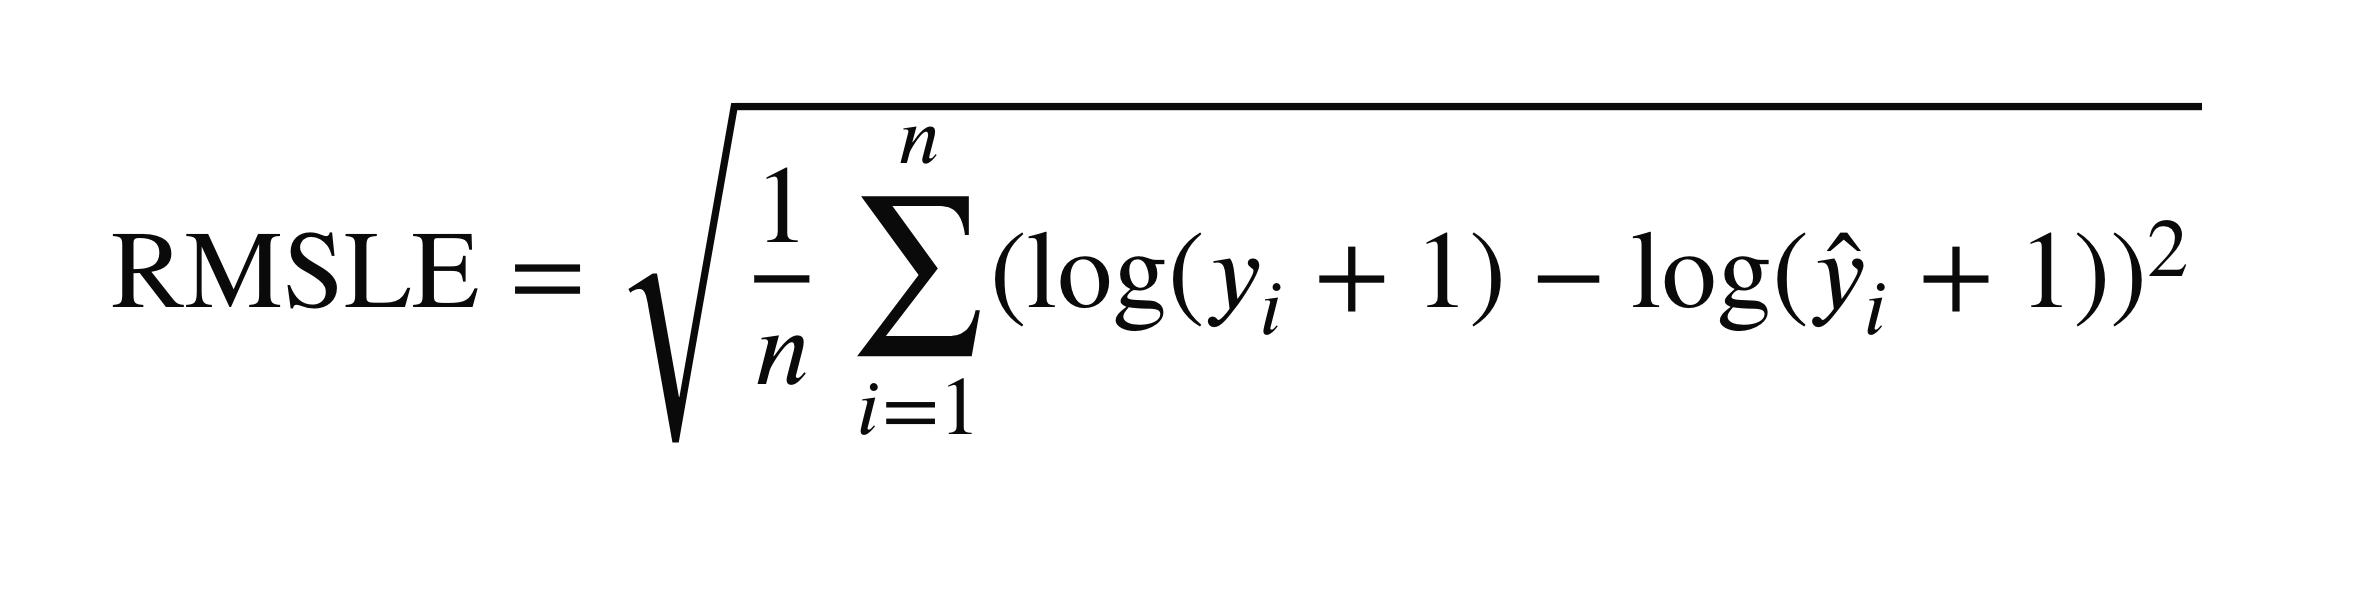


where:

- **`n`** is the number of rows being evaluated.

- **`yᵢ`** is the actual `TargetValue` from the **training data**.

- **`ŷᵢ`** is the `TargetValue` predicted by the model.

- During training and validation, I can compare **actual values with predicted values** because the training data contains `TargetValue`.

- The **test data does not contain `TargetValue`**, so I cannot calculate RMSLE directly on the test set.

- Instead, I evaluate my models on validation data and select the model with the **lowest RMSLE**.

- I then train the selected model and use it to predict `TargetValue` for the test data.

- then these test predictions are compared against the actual values to calculate the score.

RMSLE measures the difference between actual and predicted values on a **logarithmic scale**, The log scale focuses more on the relative error rather than just the absolute difference between the actual and predicted values. 

A **lower RMSLE is better**, while **RMSLE = 0 represents perfect predictions**.

I use **`np.log1p()`** to transform `TargetValue` into `log(1 + TargetValue)` before modelling and **`np.expm1()`** to convert predictions back to the original scale before creating the final submission.

### 1. Setup, Libraries and Evaluation Function

In this cell, all the libraries required for data handling, visualisation, preprocessing, model training and hyperparameter tuning are imported.

Keeping the imports and global settings together makes the notebook easier to read.

I use the same `RANDOM_STATE = 42` in different models so that random operations are repeatable.

The target is stored in:

`TARGET = "TargetValue"`

so I do not have to repeatedly type the target column name.

- `warnings.filterwarnings("ignore")` hides warning messages. 
- `random.seed()` and `np.random.seed()` improve reproducibility.
- `train_test_split` creates training and validation subsets.
- `GridSearchCV` and `RandomizedSearchCV` are used for hyperparameter tuning.
- `SimpleImputer` handles missing numerical values.
- `OrdinalEncoder` converts categories into numerical codes.
- `LGBMRegressor` and `CatBoostRegressor` are gradient-boosting models.
- `mean_squared_error` is used inside my evaluation function.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from lightgbm import LGBMRegressor, early_stopping, log_evaluation
from catboost import CatBoostRegressor

RANDOM_STATE = 42
TARGET = "TargetValue"

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)


def log_rmse(y_true_log, y_pred_log):
    return np.sqrt(mean_squared_error(y_true_log, y_pred_log))


## 2. Loading the Data

Here the data path and load four CSV files are loaded:

- Training data
- Test data
- Sample submission
- Metadata

The training dataset contains the features and known `TargetValue`.
The test dataset contains the features for which I need to make predictions.
The sample submission shows the exact format expected by Kaggle.
The metadata helps me understand the meaning of the dataset columns.

In [2]:
DATA_PATH = (
    "/kaggle/input/competitions/"
    "heavy-equipment-selling-price-prediction-challenge"
)

train = pd.read_csv(
    f"{DATA_PATH}/train.csv",
    low_memory=False
)

test = pd.read_csv(
    f"{DATA_PATH}/test.csv",
    low_memory=False
)

sample_submission = pd.read_csv(
    f"{DATA_PATH}/sample_submission.csv"
)

metadata = pd.read_csv(
    f"{DATA_PATH}/metadata.csv"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission shape:", sample_submission.shape)

display(train.head())
display(metadata.head(10))

Train shape: (138701, 50)
Test shape: (15000, 49)
Submission shape: (15000, 2)


,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.0,117665,88,ACH138,GTX,1997,4640.0,Low,2005-03-26,950FII,950,F,II,NaN,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,23.5,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.0,1001282,4616,ACH138,GTX,2005,508.0,Low,2009-12-18,310G,310,G,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Extended,Powershuttle,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.0,772709,1948,ACH138,GTX,1994,11540.0,High,2005-08-26,790ELC,790,E,NaN,LC,Large / Medium,"Hydraulic Excavator, Track - 21.0 to 24.0 Metr...",Florida,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN
3,1139322,27000.0,902010,3550,ACH138,GTX,2002,4883.0,High,2006-11-17,416D,416,D,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Illinois,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Standard,Standard,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1139333,21500.0,1036259,36014,ACH138,GTX,2009,302.0,Low,2010-08-27,430HAG,430,HAG,NaN,NaN,Mini,"Hydraulic Excavator, Track - 3.0 to 4.0 Metric...",Texas,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Auxiliary,NaN,NaN,NaN,NaN,NaN,Manual,NaN,NaN,Rubber,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN


,Variable,Rephrased Description
0,TransactionID,A unique serial number assigned to each indivi...
1,TargetValue,"The financial amount of the transaction, denom..."
2,AssetID,The internal tracking number assigned to a spe...
3,ProductConfigID,A system-generated code representing the techn...
4,DataOriginCode,A code indicating the specific software or pla...
5,VendorPartnerID,The unique ID of the external entity or third-...
6,TransactionDate,The official calendar date when the entry was ...
7,RegionCode,The specific geographic area or legal jurisdic...
8,ManufactureYear,The year the asset was originally produced.
9,OperationalHoursMeter,The lifetime total of active run-time or work ...


`pd.read_csv()` loads a CSV file into a Pandas DataFrame.
`low_memory=False` tells Pandas to process column type inference more consistently.
`.shape` returns:
`(number of rows, number of columns)`
`head()` allows me to inspect sample observations.


The training dataset should contain one more column than the test dataset because only training contains `TargetValue`.

Before performing EDA or modelling, I need to confirm that the correct datasets were loaded and understand their basic structure.

### 3. EDA - Duplicates, Missing Values and Main Distributions


In this section, I perform the first Exploratory Data Analysis (EDA) to understand the quality and distribution of the training data.

I investigate:

- Duplicate rows
- Missing target values
- Features with the most missing values
- `TargetValue` distribution
- Log-transformed `TargetValue`
- `ManufactureYear` distribution

Before cleaning or modelling the data, I need to understand the problems present in the raw dataset.

This analysis helps me decide:
- whether duplicate rows need to be removed,
- whether any rows are missing the target,
- how missing predictor values should be handled,
- whether the target is skewed,
- and whether `ManufactureYear` contains unusual values.

I also compare the original target with its log-transformed version because the competition uses RMSLE, which evaluates prediction errors on a logarithmic scale.

Duplicate rows: 0
Missing target values: 0


,Missing Percentage
col19,99.952416
col18,99.952416
col5,92.515555
col4,92.515555
col27,89.214930
col28,89.214930
col29,86.393753
col30,86.393753
col13,83.125572
col14,83.125572


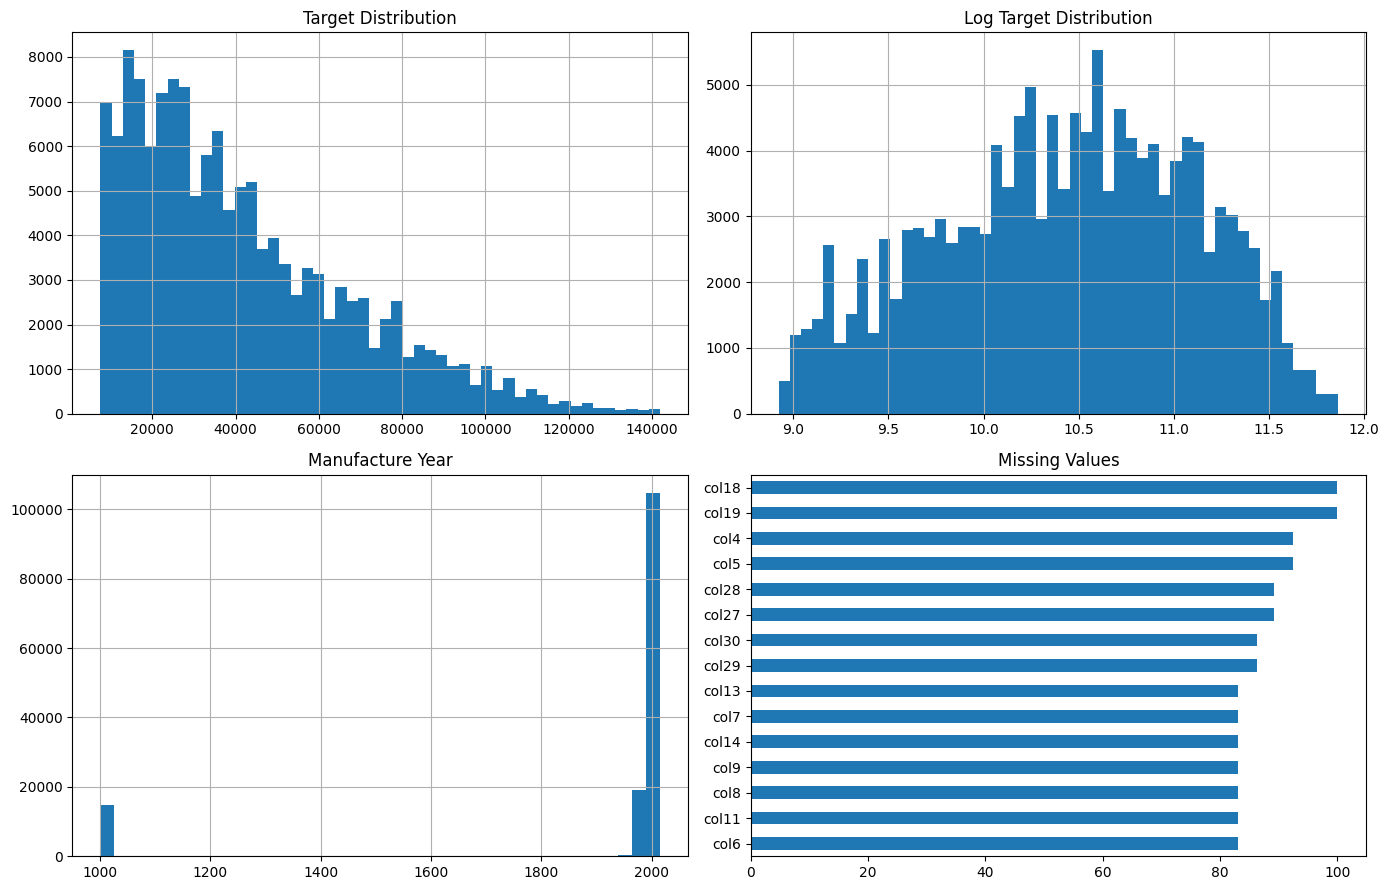

In [3]:
print("Duplicate rows:", train.duplicated().sum())
print("Missing target values:", train[TARGET].isna().sum())

missing_values = (
    train.isna()
    .mean()
    .sort_values(ascending=False)
    .head(15) * 100
)

display(
    missing_values.to_frame("Missing Percentage")
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

train[TARGET].hist(
    bins=50,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Target Distribution")

np.log1p(train[TARGET]).hist(
    bins=50,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Log Target Distribution")

train["ManufactureYear"].hist(
    bins=40,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Manufacture Year")

missing_values.sort_values().plot(
    kind="barh",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Missing Values")

plt.tight_layout()
plt.show()

Duplicate and Missing Values

I check for **duplicate rows** because repeated observations could affect model training.

I also check for **missing TargetValues** because supervised learning requires a known target during training.

For the other features, I calculate the percentage of missing values and display the **15 columns with the most missing data**. These missing values are handled later during preprocessing.

Target Distribution

The `TargetValue` histogram is **right-skewed**. Most transactions are in the lower range, while a smaller number have very large values.

I therefore also plot `log1p(TargetValue)`. The log transformation reduces the effect of very large values and makes the distribution less skewed. This also matches the **RMSLE** evaluation metric, so I later train my models using the log-transformed target.

Manufacture Year

I examine `ManufactureYear` to understand the equipment age distribution and identify unrealistic year values. Invalid years are cleaned later.


Based on the EDA, 
- Remove duplicate rows and rows without a target.
- Clean invalid manufacturing years.
- Handle missing feature values during preprocessing.
- Train the models using `log1p(TargetValue)`.

The EDA helped me identify data-quality problems and showed that the target is right-skewed, which supports using a log transformation.

## 4. EDA -  Operational Hours and Region
In this EDA, I look at how two features relate to `TargetValue`:

- `OperationalHoursMeter` - how much the machine has been used.
- `RegionCode` - the region where the transaction is recorded.

I use a scatter plot to compare operational hours with selling price and a bar chart to compare the median selling price across the top 15 regions.

For the scatter plot, I use a sample of up to 20,000 rows so the graph is easier to read.

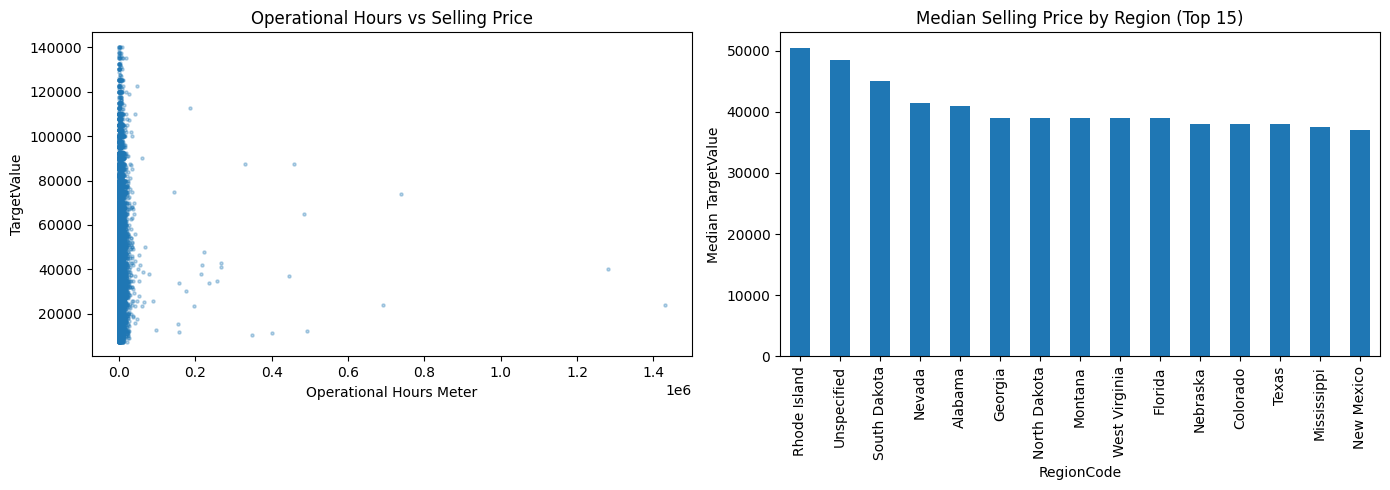

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample_for_plot = train.sample(
    n=min(20000, len(train)),
    random_state=RANDOM_STATE
)

axes[0].scatter(
    sample_for_plot["OperationalHoursMeter"],
    sample_for_plot[TARGET],
    s=5,
    alpha=0.3
)
axes[0].set_xlabel("Operational Hours Meter")
axes[0].set_ylabel(TARGET)
axes[0].set_title("Operational Hours vs Selling Price")

median_by_region = (
    train.groupby("RegionCode")[TARGET]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

median_by_region.plot(
    kind="bar",
    ax=axes[1]
)
axes[1].set_title("Median Selling Price by Region (Top 15)")
axes[1].set_ylabel("Median " + TARGET)

plt.tight_layout()
plt.show()

Observations
The scatter plot helps me see whether the amount a machine has been used is related to its `TargetValue`.
This supports creating features such as `LogOperationalHours` and `HoursPerYear` later.

Selling Price by Region
The second graph shows that the median selling price varies between regions.
I use the median because it is less affected by unusually high or low prices than the mean.

This suggests that `RegionCode` may provide useful information to the models.

I keep both **operational usage** and **regional information** and use them during feature engineering and model training.

## 5. Data Cleaning

In this section, the data is cleant before feature engineering and model training.

- Remove duplicate training rows.
- Remove rows where `TargetValue` is missing.
- Treat `ManufactureYear` values outside **1900–2020** as missing.
- Treat negative `OperationalHoursMeter` values as missing.

Instead of deleting a whole row because one feature is invalid, I convert the invalid value to `NaN` so it can be handled later during preprocessing.

I apply the same feature-cleaning rules to both the training and test data.

In [5]:
train = train.drop_duplicates().reset_index(drop=True)

train = train[
    train[TARGET].notna()
].reset_index(drop=True)

train["ManufactureYear"] = train["ManufactureYear"].where(
    train["ManufactureYear"].between(1900, 2020)
)

test["ManufactureYear"] = test["ManufactureYear"].where(
    test["ManufactureYear"].between(1900, 2020)
)

train["OperationalHoursMeter"] = train[
    "OperationalHoursMeter"
].where(
    train["OperationalHoursMeter"] >= 0
)

test["OperationalHoursMeter"] = test[
    "OperationalHoursMeter"
].where(
    test["OperationalHoursMeter"] >= 0
)

print("Clean train shape:", train.shape)
print("Clean test shape:", test.shape)

Clean train shape: (138701, 50)
Clean test shape: (15000, 49)


Cleaning Results
After cleaning, I print the new shapes of the training and test datasets to check how the data has changed.

- **Duplicates** are removed so repeated rows do not influence the training set.
- Rows with a **missing `TargetValue`** are removed because the model needs a known target to learn from.
- Invalid `ManufactureYear` values are changed to missing rather than treated as real years.
- Negative operational hours are also changed to missing because they are not meaningful.

These missing feature values are handled later using preprocessing and imputation.

I remove unusable rows but keep rows where only an individual feature is invalid, because the other information in that row may still be useful.

## 6. Feature Engineering



In this section, I create new features from the existing data to help the models understand the information better.

- Date features such as year, month, quarter and day.
- `MachineAge` from transaction year and manufacture year.
- `LogOperationalHours` to reduce the effect of very large usage values.
- `HoursPerYear` to represent how heavily a machine has been used for its age.
- `MissingCount` to count missing values in each row.
- `ManufactureDecade` to group machines by manufacturing period.
- Combined categorical features such as `ProductFamily`, `ProductSeries`, `InventoryFamily` and `RegionInventory`.

I use one `create_features()` function so the same feature engineering is applied to both train and test data.

In [6]:
def create_features(data):
    data = data.copy()

    transaction_date = pd.to_datetime(
        data["TransactionDate"],
        errors="coerce"
    )

    data["TransactionYear"] = transaction_date.dt.year
    data["TransactionMonth"] = transaction_date.dt.month
    data["TransactionQuarter"] = transaction_date.dt.quarter
    data["TransactionDay"] = transaction_date.dt.day
    data["TransactionDayOfWeek"] = transaction_date.dt.dayofweek
    data["TransactionDayOfYear"] = transaction_date.dt.dayofyear

    data["MachineAge"] = (
        data["TransactionYear"] -
        data["ManufactureYear"]
    )

    data["MachineAge"] = data["MachineAge"].where(
        data["MachineAge"].between(0, 100)
    )

    data["LogOperationalHours"] = np.log1p(
        data["OperationalHoursMeter"].clip(lower=0)
    )

    data["HoursPerYear"] = (
        data["OperationalHoursMeter"] /
        data["MachineAge"].clip(lower=1)
    )

    data["HoursPerYear"] = data["HoursPerYear"].replace(
        [np.inf, -np.inf],
        np.nan
    )

    data["MissingCount"] = data.isna().sum(axis=1)

    data["ManufactureDecade"] = (
        data["ManufactureYear"] // 10
    ) * 10

    data["ProductFamily"] = (
        data["Spec_BaseClass"].fillna("Missing").astype(str)
        + "_"
        + data["Spec_SubClass"].fillna("Missing").astype(str)
    )

    data["ProductSeries"] = (
        data["Spec_ReleaseSeries"].fillna("Missing").astype(str)
        + "_"
        + data["Spec_VariantModifier"].fillna("Missing").astype(str)
    )

    data["InventoryFamily"] = (
        data["InventoryGroupCategory"]
        .fillna("Missing")
        .astype(str)
        + "_"
        + data["FunctionalClassification"]
        .fillna("Missing")
        .astype(str)
    )

    data["RegionInventory"] = (
        data["RegionCode"].fillna("Missing").astype(str)
        + "_"
        + data["InventoryGroupCategory"]
        .fillna("Missing")
        .astype(str)
    )

    data = data.drop(
        columns=["TransactionDate"],
        errors="ignore"
    )

    return data


X = create_features(
    train.drop(columns=TARGET)
)

X_test = create_features(test)

y_log = np.log1p(train[TARGET])

print("Training features:", X.shape)
print("Test features:", X_test.shape)

Training features: (138701, 63)
Test features: (15000, 63)


Feature Engineering Results

The new features give the models more useful information than some of the original columns alone.
I chose these columns based on patterns that I saw in EDA.

For example:

- `MachineAge` tells me how old the machine was at the time of the transaction.
- `HoursPerYear` combines machine age and operational hours to represent usage intensity.
- `ProductFamily` and the other combined features allow the models to learn relationships between related categories.
- `MissingCount` allows the model to use the amount of missing information as a possible signal.

After extracting useful information from `TransactionDate`, I remove the original date column.

Finally, I create:

`y_log = np.log1p(train[TARGET])`

This means the models are trained to predict the log-transformed TargetValue, which is suitable for the RMSLE evaluation metric.

I use feature engineering to turn the raw data into features that may have a stronger relationship with `TargetValue`.



## 7. Preparing Features and Train-Validation Split

In this section, I prepare the features before preprocessing and model training.

- Convert identifier columns such as `TransactionID` and `AssetID` to categorical/string values.
- Separate the features into **categorical** and **numerical** columns.
- Replace missing categorical values with `"Missing"`.
- Convert numerical features into numeric format.
- Split the training data into **80% training** and **20% validation** data.

The training set is used to train the models, while the validation set is used to test how well they perform on unseen data.

In [7]:
identifier_columns = [
    "TransactionID",
    "AssetID",
    "ProductConfigID",
    "VendorPartnerID",
    "DataOriginCode"
]

for column in identifier_columns:
    if column in X.columns:
        X[column] = X[column].fillna(-1).astype(str)
        X_test[column] = X_test[column].fillna(-1).astype(str)

categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = [
    column
    for column in X.columns
    if column not in categorical_columns
]

for column in categorical_columns:
    X[column] = X[column].fillna("Missing").astype(str)
    X_test[column] = X_test[column].fillna("Missing").astype(str)

for column in numerical_columns:
    X[column] = pd.to_numeric(
        X[column],
        errors="coerce"
    )

    X_test[column] = pd.to_numeric(
        X_test[column],
        errors="coerce"
    )

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y_log,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Train rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))

Train rows: 110960
Validation rows: 27741
Categorical features: 50
Numerical features: 13


The output shows:

- The number of rows used for training.
- The number of rows kept for validation.
- The number of categorical features.
- The number of numerical features.

I convert identifier columns to strings because values such as `TransactionID` are identifiers rather than measurements, so their numerical size should not automatically be treated as meaningful.


`test_size = 0.20`
which keeps 20% of the labelled data for validation.

`random_state = 42`
so I get the same split each time I run the notebook.


The validation set gives me unseen labelled data for comparing my models before making predictions on the actual test dataset.

I prepare the feature types and create an 80/20 split so I can train my models and then evaluate them fairly on unseen validation data.

## 8. Preprocessing - Missing Values and Encoding

In this section, I prepare the data so it can be used by models such as Ridge Regression and Random Forest.

- Fill missing numerical values using the **median**.
- Convert categorical values into numbers using `OrdinalEncoder`.
- Combine the numerical and categorical features back into one dataset.

I fit the imputer and encoder only on the training data, and then use them to transform the validation and test data.

This helps prevent data leakage, which means the model does not learn information from the validation or test data before evaluation.

In [8]:
numeric_imputer = SimpleImputer(strategy="median")
numeric_imputer.fit(X_train[numerical_columns])

X_train_num = numeric_imputer.transform(X_train[numerical_columns])
X_valid_num = numeric_imputer.transform(X_valid[numerical_columns])
X_test_num = numeric_imputer.transform(X_test[numerical_columns])

categorical_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)
categorical_encoder.fit(X_train[categorical_columns])

X_train_cat = categorical_encoder.transform(X_train[categorical_columns])
X_valid_cat = categorical_encoder.transform(X_valid[categorical_columns])
X_test_cat = categorical_encoder.transform(X_test[categorical_columns])

encoded_columns = numerical_columns + categorical_columns

X_train_enc = pd.DataFrame(
    np.hstack([X_train_num, X_train_cat]),
    columns=encoded_columns,
    index=X_train.index
)

X_valid_enc = pd.DataFrame(
    np.hstack([X_valid_num, X_valid_cat]),
    columns=encoded_columns,
    index=X_valid.index
)

X_test_enc = pd.DataFrame(
    np.hstack([X_test_num, X_test_cat]),
    columns=encoded_columns,
    index=X_test.index
)

print("Encoded train shape:", X_train_enc.shape)
print("Any missing values left in encoded train:", X_train_enc.isna().sum().sum())

Encoded train shape: (110960, 63)
Any missing values left in encoded train: 0


Preprocessing Results

`SimpleImputer` fills missing numerical values using the median of each column. The median is used because it is less affected by very high or very low values.

`strategy="median"` tells the imputer specifically to use the median when replacing missing values.

`OrdinalEncoder` converts each unique category into a numerical code so the model can process it. The numbers are only codes and do not represent the actual size of the categories.

`handle_unknown="use_encoded_value"` allows the encoder to handle a category that was not present when it was trained instead of giving an error.

`unknown_value=-1` tells the encoder to give any new or unseen category the code `-1`.

`fit()` learns information from the training data. For the imputer it learns the median values, and for the encoder it learns the different categories.

`transform()` applies the information learned during `fit()` to the train, validation and test data.

I only use `fit()` on the training data to prevent **data leakage**, where information from the validation or test data influences training.

`np.hstack()` joins the processed numerical and categorical columns side by side into one dataset.

`pd.DataFrame()` converts the combined data back into a DataFrame and gives it the correct column names and row indexes.

`isna().sum().sum()` counts the total number of missing values left in the processed training data.

After preprocessing, the data is numerical and ready to be used by models such as Ridge Regression and Random Forest.

## 9. Ridge Regression

In this section, I train my first model, **Ridge Regression**.

Ridge is a linear regression model that uses **regularisation** to reduce overfitting.

I use `GridSearchCV` to test different values of `alpha` and find the best setting.

I then compare the training RMSLE and validation RMSLE to see how well the model performs on unseen data.

In [9]:
ridge_param_grid = {
    "alpha": [0.1, 1.0, 5.0, 10.0, 50.0, 100.0]
}

ridge_search = GridSearchCV(
    estimator=Ridge(random_state=RANDOM_STATE),
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=-1
)

ridge_search.fit(X_train_enc, y_train)

ridge_model = ridge_search.best_estimator_

ridge_train_predictions = ridge_model.predict(X_train_enc)
ridge_valid_predictions = ridge_model.predict(X_valid_enc)

ridge_train_score = log_rmse(y_train, ridge_train_predictions)
ridge_valid_score = log_rmse(y_valid, ridge_valid_predictions)

print("Best alpha:", ridge_search.best_params_["alpha"])
print("Ridge Train RMSLE:", ridge_train_score)
print("Ridge Validation RMSLE:", ridge_valid_score)

Best alpha: 1.0
Ridge Train RMSLE: 0.46763376584626537
Ridge Validation RMSLE: 0.505806200435283


Ridge Regression Results

`Ridge` is a linear regression model that adds a penalty to large model coefficients. This helps control the model and reduce overfitting.

`alpha` controls the strength of this penalty. A larger `alpha` gives stronger regularisation, while a smaller `alpha` gives weaker regularisation.

`GridSearchCV` tests all the `alpha` values I provided and selects the one that performs best using cross-validation.

`cv=3` divides the training data into 3 parts. The model trains on 2 parts and validates on the remaining part, repeating this so each part is used for validation.

`scoring="neg_root_mean_squared_error"` tells GridSearchCV to compare the models using RMSE. It is negative because GridSearchCV is designed to choose the highest score, while a lower error is better.

`n_jobs=-1` tells Python to use all available CPU cores to make the search faster.

`fit()` trains the Ridge models and searches for the best `alpha`.

`best_estimator_` gives me the Ridge model with the best `alpha` found by GridSearchCV.

`predict()` uses the selected model to predict values for the training and validation data.

`log_rmse()` calculates the prediction error in log space. Because my target was transformed using `log1p`, this represents RMSLE.


I compare training RMSLE with validation RMSLE. Lower RMSLE is better, and the validation score tells me how well Ridge performs on unseen data.

## 10. Random Forest Regression


In this section, I train my second model, **Random Forest Regression**.

Random Forest combines many decision trees that are trained independently and averages their predictions. This makes the overall prediction more stable and reduces variance. This allows it to learn more complex and non-linear relationships than Ridge Regression.

I use `RandomizedSearchCV` to test different Random Forest settings and find a better combination of hyperparameters.

I then compare the training RMSLE and validation RMSLE to check how well the model performs on unseen data.

In [10]:
rf_param_distributions = {
    "n_estimators": [200, 300, 400],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_distributions=rf_param_distributions,
    n_iter=6,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_search.fit(X_train_enc, y_train)

random_forest_model = rf_search.best_estimator_

rf_train_predictions = random_forest_model.predict(X_train_enc)
rf_valid_predictions = random_forest_model.predict(X_valid_enc)

rf_train_score = log_rmse(y_train, rf_train_predictions)
rf_valid_score = log_rmse(y_valid, rf_valid_predictions)

print("Best parameters:", rf_search.best_params_)
print("Random Forest Train RMSLE:", rf_train_score)
print("Random Forest Validation RMSLE:", rf_valid_score)

Best parameters: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_depth': None}
Random Forest Train RMSLE: 0.10379668156555207
Random Forest Validation RMSLE: 0.2537854629418273


Random Forest Results

`RandomForestRegressor` builds many decision trees and combines their predictions. Using multiple trees usually gives a more stable prediction than using one decision tree.

`n_estimators` controls the number of trees in the forest. More trees can make predictions more stable, but also take longer to train.

`max_depth` controls how deep each tree can grow. Deeper trees can learn more complex patterns but may also overfit.

`min_samples_leaf` controls the minimum number of observations required at the end of a tree branch. Larger values make the trees less complex and can reduce overfitting.

`RandomizedSearchCV` tests a random selection of hyperparameter combinations instead of testing every possible combination.

`n_iter=6` means it tests 6 different combinations of the Random Forest settings.

`cv=3` uses 3-fold cross-validation to evaluate each combination.

`scoring="neg_root_mean_squared_error"` compares the models using RMSE. It is negative because the search selects the highest score, while a lower error is better.

`n_jobs=-1` uses all available CPU cores to make training faster.

`best_estimator_` gives me the Random Forest model with the best settings found during the search.

`predict()` uses this selected model to make predictions on the training and validation data.

`log_rmse()` calculates the error in log space. Since my target was transformed using `log1p`, this represents RMSLE.


I compare the training RMSLE and validation RMSLE. Lower RMSLE is better, and a large difference between the two scores can indicate overfitting.

## 11. Preparing Data for LightGBM

LightGBM (Light Gradient Boosting Machine) is a tree-based model. It builds trees one after another, with each new tree trying to improve the errors made by the previous trees.

LightGBM can also work directly with categorical features.

I prepare the train, validation and test data specifically for LightGBM.

`copy()` creates separate copies so I do not change the original data.

`pd.concat()` combines the category values from train, validation and test.

`unique()` finds all the different categories.

`pd.Categorical()` tells LightGBM that these values are categories rather than normal numerical values.

I use the same categories across all three datasets so they are represented consistently.

In [11]:
X_train_lgb = X_train.copy()
X_valid_lgb = X_valid.copy()
X_test_lgb = X_test.copy()

for column in categorical_columns:
    all_categories = pd.Index(
        pd.concat(
            [
                X_train_lgb[column],
                X_valid_lgb[column],
                X_test_lgb[column]
            ]
        ).unique()
    )

    X_train_lgb[column] = pd.Categorical(
        X_train_lgb[column],
        categories=all_categories
    )

    X_valid_lgb[column] = pd.Categorical(
        X_valid_lgb[column],
        categories=all_categories
    )

    X_test_lgb[column] = pd.Categorical(
        X_test_lgb[column],
        categories=all_categories
    )

print("LightGBM data prepared.")

LightGBM data prepared.


## 12. LightGBM

In this section, I train my **LightGBM regression model** on the log-transformed target.

LightGBM builds decision trees one after another, where each new tree tries to correct the errors made by the previous trees.

I use the validation data during training and use **early stopping** to stop adding trees when the validation performance is no longer improving.

Finally, I calculate the training and validation RMSLE to evaluate the model.

In [12]:
lightgbm_model = LGBMRegressor(
    objective="regression",
    n_estimators=5000,
    learning_rate=0.02,
    num_leaves=128,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_alpha=0.10,
    reg_lambda=0.20,
    max_bin=255,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

lightgbm_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[
        (X_valid_lgb, y_valid)
    ],
    eval_metric="rmse",
    categorical_feature=categorical_columns,
    callbacks=[
        early_stopping(
            stopping_rounds=200,
            verbose=False
        ),
        log_evaluation(period=0)
    ]
)

lightgbm_train_predictions = lightgbm_model.predict(
    X_train_lgb,
    num_iteration=lightgbm_model.best_iteration_
)

lightgbm_valid_predictions = lightgbm_model.predict(
    X_valid_lgb,
    num_iteration=lightgbm_model.best_iteration_
)

lightgbm_train_score = log_rmse(
    y_train,
    lightgbm_train_predictions
)

lightgbm_score = log_rmse(
    y_valid,
    lightgbm_valid_predictions
)

print("LightGBM Train RMSLE:", lightgbm_train_score)
print("LightGBM Validation RMSLE:", lightgbm_score)
print("Best iteration:", lightgbm_model.best_iteration_)

LightGBM Train RMSLE: 0.08802936971225293
LightGBM Validation RMSLE: 0.2002825063104443
Best iteration: 5000


LightGBM Results

`objective="regression"` tells LightGBM that I am predicting a continuous numerical value.

`n_estimators=5000` sets the maximum number of trees that LightGBM can build.

`learning_rate=0.02` controls how much each new tree contributes to the model. A smaller learning rate makes the model learn more gradually.

`num_leaves=127` controls the maximum number of leaves in each tree. More leaves allow the model to learn more complex patterns.

`max_depth=-1` means I do not set a fixed maximum depth for the trees.

`min_child_samples=20` requires at least 20 observations in a leaf, which helps prevent the model from creating very small and overly specific groups.

`subsample=0.90` allows the model to use 90% of the rows when sampling is active, while `colsample_bytree=0.90` uses 90% of the features for each tree.

`reg_alpha` and `reg_lambda` add regularisation, which helps control the complexity of the model and reduce overfitting.

`eval_set` gives LightGBM the validation data so it can check its performance while training.

`early_stopping(stopping_rounds=150)` stops training if the validation RMSE does not improve for 150 rounds. This helps prevent unnecessary training and overfitting.

`best_iteration_` stores the number of trees that gave the best validation performance.

`predict()` uses the trained model at its best iteration to make predictions.

Finally, I compare the training RMSLE and validation RMSLE. Lower RMSLE means better predictions.

## 13. CatBoost

In this section, I train my **CatBoost regression model**.

**CatBoost (Categorical Boosting)** is a tree-based boosting model. It builds trees one after another, with each new tree trying to reduce the errors made by the previous trees.

CatBoost is especially useful for datasets with many categorical features because it can handle categorical data directly without using `OrdinalEncoder`.

I train the model using the training data and monitor its performance on the validation data using early stopping.

In [13]:
catboost_model = CatBoostRegressor(
    iterations=2200,
    learning_rate=0.045,
    depth=9,
    loss_function="RMSE",
    eval_metric="RMSE",
    l2_leaf_reg=7,
    random_strength=0.25,
    bagging_temperature=0.4,
    border_count=128,
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
    verbose=False,
    thread_count=-1
)

catboost_model.fit(
    X_train,
    y_train,
    cat_features=categorical_columns,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=120,
    verbose=False
)

catboost_train_predictions = catboost_model.predict(X_train)
catboost_valid_predictions = catboost_model.predict(X_valid)

catboost_train_score = log_rmse(
    y_train,
    catboost_train_predictions
)

catboost_score = log_rmse(
    y_valid,
    catboost_valid_predictions
)

print("CatBoost Train RMSLE:", catboost_train_score)
print("CatBoost Validation RMSLE:", catboost_score)
print(
    "Best iteration:",
    catboost_model.get_best_iteration()
)

CatBoost Train RMSLE: 0.1860021287849197
CatBoost Validation RMSLE: 0.20685981400983133
Best iteration: 2199


CatBoost Results

`iterations=2200` sets the maximum number of boosting rounds or trees the model can build.

`learning_rate=0.045` controls how much each new tree contributes. A smaller value makes the model learn more gradually.

`depth=9` controls how deep each tree can grow. Deeper trees can learn more complex patterns but can also increase overfitting.

`loss_function="RMSE"` tells CatBoost what error it should try to minimise during training.

`eval_metric="RMSE"` tells CatBoost to use RMSE when checking performance on the validation data.

`l2_leaf_reg=7` adds regularisation to control the complexity of the model and reduce overfitting.

`random_strength=0.25` adds randomness when choosing tree splits, which can help reduce overfitting.

`bagging_temperature=0.4` controls the randomness used when selecting training observations for the trees.

`border_count=128` controls how many split points CatBoost can consider for numerical features.

`cat_features=categorical_columns` tells CatBoost which columns contain categorical data so it can handle them directly.

`early_stopping_rounds=120` stops training if the validation RMSE does not improve for 120 rounds.

`predict()` uses the trained model to make predictions.

`get_best_iteration()` returns the boosting round that produced the best validation performance.

I compare the training RMSLE and validation RMSLE. Lower RMSLE means better predictions, while a large gap between them can indicate overfitting.

## 14. Model Comparison

In this section, I compare all four models using their **training and validation RMSLE**.

The main score I use to choose the better model is Validation RMSLE, because it shows how well the model performs on unseen data.

I also calculate the overfitting gap, which is the difference between validation and training RMSLE.

A lower RMSLE is better.

,Model,Train RMSLE,Validation RMSLE,Overfitting Gap
0,LightGBM (boosting),0.088029,0.200283,0.112253
1,CatBoost (boosting),0.186002,0.206860,0.020858
2,Random Forest (bagging),0.103797,0.253785,0.149989
3,Ridge Regression (linear),0.467634,0.505806,0.038172


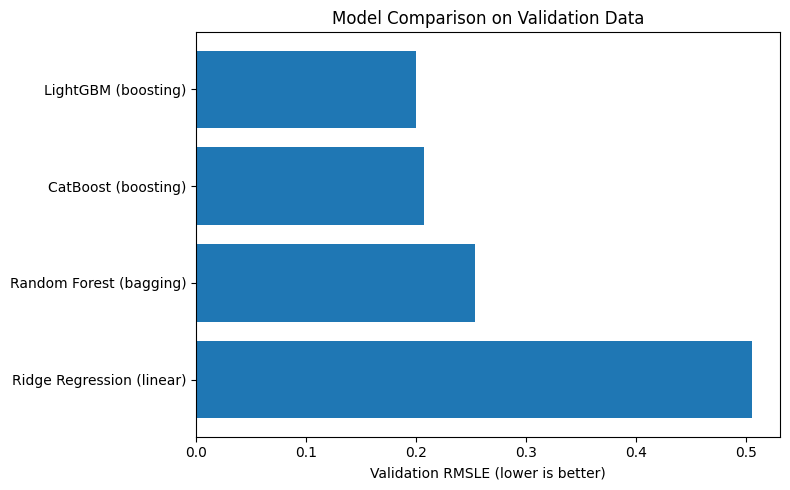

In [14]:
model_comparison = pd.DataFrame({
    "Model": [
        "Ridge Regression (linear)",
        "Random Forest (bagging)",
        "LightGBM (boosting)",
        "CatBoost (boosting)"
    ],
    "Train RMSLE": [
        ridge_train_score,
        rf_train_score,
        lightgbm_train_score,
        catboost_train_score
    ],
    "Validation RMSLE": [
        ridge_valid_score,
        rf_valid_score,
        lightgbm_score,
        catboost_score
    ]
})

model_comparison["Overfitting Gap"] = (
    model_comparison["Validation RMSLE"] -
    model_comparison["Train RMSLE"]
)

model_comparison = model_comparison.sort_values(
    "Validation RMSLE"
).reset_index(drop=True)

display(model_comparison)

plt.figure(figsize=(8, 5))
plt.barh(
    model_comparison["Model"],
    model_comparison["Validation RMSLE"]
)
plt.xlabel("Validation RMSLE (lower is better)")
plt.title("Model Comparison on Validation Data")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Model Comparison Results

`pd.DataFrame()` puts the results of all four models into one table so they can be compared easily.

`Overfitting Gap` is calculated as **Validation RMSLE - Train RMSLE**. A large gap means the model performs much better on training data than unseen validation data, which can indicate overfitting.

`sort_values("Validation RMSLE")` sorts the models from best to worst because lower RMSLE is better.

The bar chart gives a visual comparison of the validation scores.

Results

- **LightGBM:**  validation RMSLE - best overall performance.
- **CatBoost:** second best and has a much smaller overfitting gap.
- **Random Forest:** performs worse and shows more overfitting.
- **Ridge Regression:** performs the worst, suggesting that the relationships in the data are not simply linear.

LightGBM has the **lowest validation RMSLE**, so it is my best individual model.

However, its training score is much lower than its validation score, which shows some overfitting. CatBoost generalises more consistently, so combining these two models may improve the final prediction.

## 15. Blending LightGBM and CatBoost

In this section, I combine the predictions from **LightGBM** and **CatBoost**.

This is called **blending**. Blending combines predictions from different models because each model may make different mistakes.

I test different weight combinations between LightGBM and CatBoost and calculate the validation RMSLE for each one.

The combination with the **lowest RMSLE** is selected as the best blend.

In [15]:
blend_results = []

for lightgbm_weight in np.arange(
    0.30,
    0.81,
    0.05
):
    catboost_weight = 1 - lightgbm_weight

    blended_predictions = (
        lightgbm_weight *
        lightgbm_valid_predictions
        +
        catboost_weight *
        catboost_valid_predictions
    )

    blend_score = log_rmse(
        y_valid,
        blended_predictions
    )

    blend_results.append({
        "LightGBMWeight": lightgbm_weight,
        "CatBoostWeight": catboost_weight,
        "RMSLE": blend_score
    })

blend_results = pd.DataFrame(
    blend_results
).sort_values(
    "RMSLE"
).reset_index(drop=True)

BEST_LGB_WEIGHT = float(
    blend_results.loc[0, "LightGBMWeight"]
)

BEST_CAT_WEIGHT = float(
    blend_results.loc[0, "CatBoostWeight"]
)

display(blend_results)

print("LightGBM score:", lightgbm_score)
print("CatBoost score:", catboost_score)
print("Best blend score:", blend_results.loc[0, "RMSLE"])
print("Best LightGBM weight:", BEST_LGB_WEIGHT)
print("Best CatBoost weight:", BEST_CAT_WEIGHT)

,LightGBMWeight,CatBoostWeight,RMSLE
0,0.60,0.40,0.195596
1,0.65,0.35,0.195643
2,0.55,0.45,0.195704
3,0.70,0.30,0.195846
4,0.50,0.50,0.195968
5,0.75,0.25,0.196204
6,0.45,0.55,0.196387
7,0.80,0.20,0.196717
8,0.40,0.60,0.196960
9,0.35,0.65,0.197686


LightGBM score: 0.2002825063104443
CatBoost score: 0.20685981400983133
Best blend score: 0.19559569240230698
Best LightGBM weight: 0.5999999999999999
Best CatBoost weight: 0.40000000000000013


Blending Results

`np.arange(0.30, 0.81, 0.05)` creates the different LightGBM weights that I want to test, from 0.30 to 0.80.

`catboost_weight = 1 - lightgbm_weight` makes sure the LightGBM and CatBoost weights always add up to 1.

`blended_predictions` combines the two model predictions using their selected weights.

`log_rmse()` calculates the RMSLE for each blend on the validation data.

`append()` stores the result of every weight combination so I can compare them later.

`sort_values("RMSLE")` sorts the combinations from best to worst because lower RMSLE is better.

`loc[0]` selects the first row after sorting, which is the blend with the lowest validation RMSLE.

Result

LightGBM alone achieved **~0.2007 RMSLE** and CatBoost achieved **~0.2069 RMSLE**.

The best blend used:

- **60% LightGBM**
- **40% CatBoost**

and achieved a validation RMSLE of **~0.19594**.

This is better than either model individually, which shows that combining the two models improved validation performance.

## 16. Feature Importance and Final Model Training

In this section, I check which features were most useful to the LightGBM model and then train my final models.

`feature_importances_` gives each feature an importance score based on how useful it was when LightGBM built its trees. A higher score means the feature was used more by the model.

I use the best iteration found during validation to decide how many iterations to use for the final LightGBM and CatBoost models.

Finally, I retrain both models using the full training dataset so they can learn from all available labelled data before predicting the test data.

In [16]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": lightgbm_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.head(25))

best_lgb_iterations = max(
    800,
    int(lightgbm_model.best_iteration_ * 1.10)
)

best_cat_iterations = max(
    800,
    int(
        catboost_model.get_best_iteration() * 1.10
    )
)

X_full_lgb = X.copy()
X_final_test_lgb = X_test.copy()

for column in categorical_columns:
    all_categories = pd.Index(
        pd.concat(
            [
                X_full_lgb[column],
                X_final_test_lgb[column]
            ]
        ).unique()
    )

    X_full_lgb[column] = pd.Categorical(
        X_full_lgb[column],
        categories=all_categories
    )

    X_final_test_lgb[column] = pd.Categorical(
        X_final_test_lgb[column],
        categories=all_categories
    )

final_lightgbm_model = LGBMRegressor(
    objective="regression",
    n_estimators=best_lgb_iterations,
    learning_rate=0.02,
    num_leaves=127,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_alpha=0.05,
    reg_lambda=0.20,
    max_bin=255,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

final_catboost_model = CatBoostRegressor(
    iterations=best_cat_iterations,
    learning_rate=0.045,
    depth=9,
    loss_function="RMSE",
    l2_leaf_reg=7,
    random_strength=0.25,
    bagging_temperature=0.4,
    border_count=128,
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
    verbose=False,
    thread_count=-1
)

final_lightgbm_model.fit(
    X_full_lgb,
    y_log,
    categorical_feature=categorical_columns,
    callbacks=[
        log_evaluation(period=0)
    ]
)

final_catboost_model.fit(
    X,
    y_log,
    cat_features=categorical_columns,
    verbose=False
)

print("Final LightGBM iterations:", best_lgb_iterations)
print("Final CatBoost iterations:", best_cat_iterations)

,Feature,Importance
53,TransactionDayOfYear,70960
51,TransactionDay,58302
54,MachineAge,55560
5,ManufactureYear,52745
62,RegionInventory,44831
48,TransactionYear,38797
6,OperationalHoursMeter,34993
2,ProductConfigID,33571
56,HoursPerYear,28188
15,RegionCode,27455


Final LightGBM iterations: 5500
Final CatBoost iterations: 2418


Feature Importance and Final Training Results

The most important LightGBM feature is `TransactionDayOfYear`, followed by `TransactionDay`, `MachineAge`, `ManufactureYear` and `RegionInventory`.

This shows that **transaction timing, machine age, manufacturing year, region and usage information** were useful to the model.

`feature_importances_` shows how useful each feature was when LightGBM built its trees. A high importance does not mean the feature causes the selling price; it only means the model found it useful for prediction.

`best_iteration_` gives the number of iterations where LightGBM achieved its best validation performance.

`get_best_iteration()` does the same for CatBoost.

I use 10% more than the best validation iteration because the final models are trained using more data than before.

`max(800, ...)` makes sure that at least 800 iterations are used.

The final LightGBM model uses **5,490 iterations** and the final CatBoost model uses **2,418 iterations**.

`fit()` then trains both models again using all of the available training data.

Both final models have now been trained using the complete labelled dataset and are ready to predict the test data.

## 17. Final Predictions and Submission

In this final section, I use the trained LightGBM and CatBoost models to predict `TargetValue` for the test data.

I combine their predictions using the best blend found during validation:

- **60% LightGBM**
- **40% CatBoost**

The models predict on the log scale, so I convert the predictions back to the original `TargetValue` scale.

Finally, I check that the predictions are valid and save them as `submission.csv` for Kaggle.

In [17]:
lightgbm_test_log = final_lightgbm_model.predict(
    X_final_test_lgb
)

catboost_test_log = final_catboost_model.predict(
    X_test
)

final_test_log = (
    BEST_LGB_WEIGHT *
    lightgbm_test_log
    +
    BEST_CAT_WEIGHT *
    catboost_test_log
)

final_predictions = np.expm1(
    final_test_log
)

final_predictions = np.clip(
    final_predictions,
    0,
    None
)

submission = sample_submission.copy()

submission[TARGET] = final_predictions

if "TransactionID" in submission.columns:
    submission["TransactionID"] = test[
        "TransactionID"
    ].values

assert len(submission) == len(test)
assert submission[TARGET].isna().sum() == 0
assert np.isfinite(submission[TARGET]).all()
assert (submission[TARGET] >= 0).all()

submission.to_csv(
    "/kaggle/working/submission.csv",
    index=False
)

display(submission.head())
display(submission[TARGET].describe())

print(
    "Saved submission to "
    "/kaggle/working/submission.csv"
)

,TransactionID,TargetValue
0,1139307,66353.578084
1,1139419,80134.805350
2,1139482,30074.525322
3,1139522,20371.463015
4,1139684,13554.299488


count     15000.000000
mean      40861.675890
std       24795.802502
min        7470.112909
25%       20992.353141
50%       34646.828470
75%       56350.824192
max      141721.627193
Name: TargetValue, dtype: float64

Saved submission to /kaggle/working/submission.csv


 Final Submission Results

`predict()` uses the final trained models to generate predictions for the test data.

`BEST_LGB_WEIGHT` and `BEST_CAT_WEIGHT` apply the best 60% LightGBM and 40% CatBoost blend found during validation.

`np.expm1()` reverses the earlier `np.log1p()` transformation and converts the predictions from the log scale back to the original `TargetValue` scale.

`np.clip(..., 0, None)` prevents negative predictions because negative values would not be meaningful for this target.

`sample_submission.copy()` keeps the required structure of the Kaggle submission file.

The `assert` statements are final safety checks. They confirm that the number of predictions matches the test data and that there are no missing, infinite or negative predictions.

`to_csv()` saves the final predictions as `submission.csv`, and `index=False` prevents an extra row-number column from being added.

Result

The final submission contains **15,000 predictions**.

The predicted `TargetValue` ranges from approximately **7,471 to 141,722**, with a median of approximately **34,645**.

The submission passes all final checks and is saved as:

`/kaggle/working/submission.csv`

